# Offline A/B Test Simulator — Off-Policy Evaluation at Scale

**Objectif** : Estimer la performance d'une nouvelle policy de recommandation *sans la déployer*, à partir des logs d'une policy existante.

**Estimateurs implémentés** : IPS, SNIPS, Doubly Robust, IPS Clippé

**Stack** : PySpark, Pandas, Open Bandit Dataset (12M+ interactions réelles)

---
## Partie 1 — Comprendre les estimateurs sur un petit exemple (6 lignes)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Policies : probabilités de montrer chaque produit
policies = pd.DataFrame({
    "produit": ["chaussures", "sac", "montre"],
    "proba_A": [0.5, 0.3, 0.2],
    "proba_B": [0.1, 0.7, 0.2]
})

# Logs observés sous policy A
logs = pd.DataFrame({
    "user": [1, 2, 3, 4, 5, 6],
    "produit_montre": ["chaussures", "chaussures", "sac", "sac", "montre", "chaussures"],
    "reward": [1, 0, 1, 1, 0, 1]
})

print("=== Policies ===")
print(policies)
print("\n=== Logs ===")
print(logs)

=== Policies ===
      produit  proba_A  proba_B
0  chaussures      0.5      0.1
1         sac      0.3      0.7
2      montre      0.2      0.2

=== Logs ===
   user produit_montre  reward
0     1     chaussures       1
1     2     chaussures       0
2     3            sac       1
3     4            sac       1
4     5         montre       0
5     6     chaussures       1


In [2]:
# Merger les logs avec les policies
df = logs.merge(policies, left_on="produit_montre", right_on="produit")

# Taux de clic observé sous policy A
moy_A = df["reward"].mean()
print(f"CTR observé (Policy A) : {moy_A:.4f}")

CTR observé (Policy A) : 0.6667


In [3]:
# Poids IPS = proba_B / proba_A
df["poids_ips"] = df["proba_B"] / df["proba_A"]

# IPS : moyenne pondérée des rewards
estimate_IPS = (df["poids_ips"] * df["reward"]).mean()

# SNIPS : normalisé par la somme des poids
estimate_SNIPS = (df["poids_ips"] * df["reward"]).sum() / df["poids_ips"].sum()

print(f"IPS:   {estimate_IPS:.4f}")
print(f"SNIPS: {estimate_SNIPS:.4f}")
print(f"\nLes poids :")
print(df[["user", "produit_montre", "reward", "poids_ips"]])

IPS:   0.8444
SNIPS: 0.8085

Les poids :
   user produit_montre  reward  poids_ips
0     1     chaussures       1   0.200000
1     2     chaussures       0   0.200000
2     3            sac       1   2.333333
3     4            sac       1   2.333333
4     5         montre       0   1.000000
5     6     chaussures       1   0.200000


In [4]:
# Doubly Robust : prédiction + correction
reward_model = {"chaussures": 0.6, "sac": 0.9, "montre": 0.3}
df["r_hat"] = df["produit_montre"].map(reward_model)

estimate_DR = (df["r_hat"] + df["poids_ips"] * (df["reward"] - df["r_hat"])).mean()

print(f"IPS:   {estimate_IPS:.4f}")
print(f"SNIPS: {estimate_SNIPS:.4f}")
print(f"DR:    {estimate_DR:.4f}")

IPS:   0.8444
SNIPS: 0.8085
DR:    0.6844


In [5]:
# Test de robustesse : changer 1 seul reward
print("=== Test de robustesse : User 4 reward 1 → 0 ===")
print()

df_modified = df.copy()
df_modified.loc[df_modified["user"] == 4, "reward"] = 0

ips_mod = (df_modified["poids_ips"] * df_modified["reward"]).mean()
snips_mod = (df_modified["poids_ips"] * df_modified["reward"]).sum() / df_modified["poids_ips"].sum()
dr_mod = (df_modified["r_hat"] + df_modified["poids_ips"] * (df_modified["reward"] - df_modified["r_hat"])).mean()

print(f"{'Estimateur':<12} {'Avant':>10} {'Après':>10} {'Chute':>10}")
print(f"{'IPS':<12} {estimate_IPS:>10.4f} {ips_mod:>10.4f} {(ips_mod/estimate_IPS - 1)*100:>9.1f}%")
print(f"{'SNIPS':<12} {estimate_SNIPS:>10.4f} {snips_mod:>10.4f} {(snips_mod/estimate_SNIPS - 1)*100:>9.1f}%")
print(f"{'DR':<12} {estimate_DR:>10.4f} {dr_mod:>10.4f} {(dr_mod/estimate_DR - 1)*100:>9.1f}%")
print()
print("→ Un seul point de données change et les estimations basculent.")
print("  C'est le problème de variance sur peu de données.")

=== Test de robustesse : User 4 reward 1 → 0 ===

Estimateur        Avant      Après      Chute
IPS              0.8444     0.4556     -46.1%
SNIPS            0.8085     0.4362     -46.1%
DR               0.6844     0.2956     -56.8%

→ Un seul point de données change et les estimations basculent.
  C'est le problème de variance sur peu de données.


---
## Partie 2 — PySpark sur données simulées (1M lignes)

In [6]:
import os
os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"

from pyspark.sql import SparkSession
import pyspark.sql.functions as F

spark = SparkSession.builder \
    .appName("OffPolicyEval") \
    .master("local[*]") \
    .getOrCreate()

print("SPARK OK")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/07/10 00:46:39 WARN Utils: Your hostname, MeryemeRamdis-MacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 192.168.100.134 instead (on interface en0)
26/07/10 00:46:39 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/07/10 00:46:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


SPARK OK


In [7]:
# Générer 1M de logs simulés avec ground truth connue
import time

np.random.seed(42)

N_PRODUCTS = 100
N_USERS = 1_000_000

# Deux policies avec des distributions différentes
policy_a = np.random.dirichlet(np.ones(N_PRODUCTS) * 5)
policy_b = np.random.dirichlet(np.ones(N_PRODUCTS) * 2)

# Vrai taux de clic par produit
true_ctr = np.random.beta(2, 20, size=N_PRODUCTS)

# Vraies valeurs des policies
true_value_A = np.sum(policy_a * true_ctr)
true_value_B = np.sum(policy_b * true_ctr)

# Générer les logs sous policy A
products_shown = np.random.choice(N_PRODUCTS, size=N_USERS, p=policy_a)
rewards = np.random.binomial(1, true_ctr[products_shown])

df_sim = pd.DataFrame({
    "user_id": np.arange(N_USERS),
    "product_id": products_shown,
    "reward": rewards,
    "propensity_a": policy_a[products_shown],
    "propensity_b": policy_b[products_shown]
})

# Sauvegarder
df_sim.to_parquet("logs_1M.parquet", index=False)

print(f"Vraie valeur Policy A : {true_value_A:.6f}")
print(f"Vraie valeur Policy B : {true_value_B:.6f}")
print(f"Logs générés : {len(df_sim):,}")
print(f"\n→ Objectif : retrouver ~{true_value_B:.6f}")

Vraie valeur Policy A : 0.086435
Vraie valeur Policy B : 0.081825
Logs générés : 1,000,000

→ Objectif : retrouver ~0.081825


In [8]:
# Charger en PySpark
df_spark = spark.read.parquet("logs_1M.parquet")

# Poids IPS
df_spark = df_spark.withColumn("poids_ips", F.col("propensity_b") / F.col("propensity_a"))

# IPS
estimate_IPS = df_spark.select(
    F.mean(F.col("poids_ips") * F.col("reward"))
).collect()[0][0]

# SNIPS
estimate_SNIPS = (
    df_spark.select(F.sum(F.col("poids_ips") * F.col("reward"))).collect()[0][0] /
    df_spark.select(F.sum(F.col("poids_ips"))).collect()[0][0]
)

# DR avec cross-fitting
df_train = df_spark.filter(F.col("user_id") % 2 == 0)
df_eval = df_spark.filter(F.col("user_id") % 2 == 1)

r_hat = df_train.groupBy("product_id").agg(F.mean("reward").alias("r_hat"))
policy_b_df = df_spark.groupBy("product_id").agg(F.first("propensity_b").alias("policy_b"))

direct = r_hat.join(policy_b_df, on="product_id") \
    .select(F.sum(F.col("policy_b") * F.col("r_hat"))).collect()[0][0]

df_eval = df_eval.join(r_hat, on="product_id")
correction = df_eval.select(
    F.mean(F.col("poids_ips") * (F.col("reward") - F.col("r_hat")))
).collect()[0][0]

estimate_DR = direct + correction

print(f"=== PySpark sur 1M lignes simulées ===")
print(f"IPS:   {estimate_IPS:.6f}")
print(f"SNIPS: {estimate_SNIPS:.6f}")
print(f"DR:    {estimate_DR:.6f}")
print(f"Cible: {true_value_B:.6f}")

=== PySpark sur 1M lignes simulées ===
IPS:   0.081718
SNIPS: 0.081690
DR:    0.082023
Cible: 0.081825


---
## Partie 3 — Analyse de variance (convergence vs taille)

In [9]:
sizes = [1000, 10000, 100000, 1000000]
n_repeats = 50
results = []

df_clean = df_spark.drop("r_hat")

for size in sizes:
    for i in range(n_repeats):
        fraction = size / 1000000
        sample = df_clean.sample(fraction=fraction, seed=i)

        train = sample.filter(F.col("user_id") % 2 == 0)
        evl = sample.filter(F.col("user_id") % 2 == 1)
        r_hat = train.groupBy("product_id").agg(F.mean("reward").alias("r_hat"))
        policy_b_s = sample.groupBy("product_id").agg(F.first("propensity_b").alias("policy_b"))

        # IPS
        ips = sample.select(F.mean(F.col("poids_ips") * F.col("reward"))).collect()[0][0]

        # SNIPS
        snips = (
            sample.select(F.sum(F.col("poids_ips") * F.col("reward"))).collect()[0][0] /
            sample.select(F.sum(F.col("poids_ips"))).collect()[0][0]
        )

        # DR
        direct = r_hat.join(policy_b_s, on="product_id") \
            .select(F.sum(F.col("policy_b") * F.col("r_hat"))).collect()[0][0]
        evl = evl.join(r_hat, on="product_id")
        correction = evl.select(
            F.mean(F.col("poids_ips") * (F.col("reward") - F.col("r_hat")))
        ).collect()[0][0]
        dr = direct + (correction if correction else 0)

        results.append({"size": size, "run": i, "IPS": ips, "SNIPS": snips, "DR": dr})

    print(f"Taille {size:>10,} terminée")

results_df = pd.DataFrame(results)

Taille      1,000 terminée
Taille     10,000 terminée
Taille    100,000 terminée
Taille  1,000,000 terminée


FileNotFoundError: [Errno 2] No such file or directory: 'figures/variance_analysis.png'

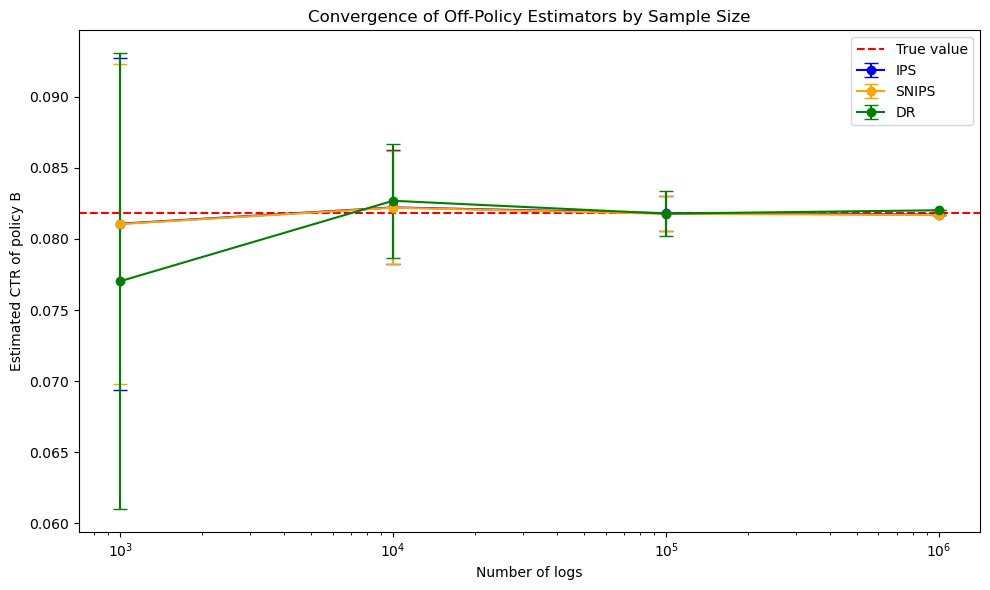

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

for estimator, color in [("IPS", "blue"), ("SNIPS", "orange"), ("DR", "green")]:
    stats = results_df.groupby("size")[estimator].agg(["mean", "std"])
    ax.errorbar(stats.index, stats["mean"], yerr=stats["std"],
                label=estimator, marker="o", capsize=5, color=color)

ax.axhline(y=true_value_B, color="red", linestyle="--", label="True value")
ax.set_xscale("log")
ax.set_xlabel("Number of logs")
ax.set_ylabel("Estimated CTR of policy B")
ax.set_title("Convergence of Off-Policy Estimators by Sample Size")
ax.legend()
plt.tight_layout()
plt.savefig("figures/variance_analysis.png", dpi=150)
plt.show()

---
## Partie 4 — Benchmark Pandas vs PySpark

In [11]:
import time

sizes = [10_000, 100_000, 500_000, 1_000_000]
timing_results = []

for size in sizes:
    # Pandas
    np.random.seed(42)
    pandas_df = pd.DataFrame({
        "propensity_a": np.random.uniform(0.005, 0.02, size),
        "propensity_b": np.random.uniform(0.005, 0.02, size),
        "reward": np.random.binomial(1, 0.08, size)
    })

    start = time.time()
    pandas_df["w"] = pandas_df["propensity_b"] / pandas_df["propensity_a"]
    ips_pandas = (pandas_df["w"] * pandas_df["reward"]).mean()
    t_pandas = time.time() - start

    # PySpark
    fraction = size / 1_000_000
    spark_df = df_clean.sample(fraction=min(fraction, 1.0), seed=42)

    start = time.time()
    spark_df = spark_df.withColumn("w", F.col("propensity_b") / F.col("propensity_a"))
    ips_spark = spark_df.select(F.mean(F.col("w") * F.col("reward"))).collect()[0][0]
    t_spark = time.time() - start

    timing_results.append({"size": size, "pandas_sec": t_pandas, "spark_sec": t_spark})
    print(f"{size:>12,} lignes | Pandas: {t_pandas:.4f}s | Spark: {t_spark:.4f}s")

timing_df = pd.DataFrame(timing_results)

      10,000 lignes | Pandas: 0.0014s | Spark: 0.0872s
     100,000 lignes | Pandas: 0.0008s | Spark: 0.0914s
     500,000 lignes | Pandas: 0.0042s | Spark: 0.1343s
   1,000,000 lignes | Pandas: 0.0086s | Spark: 0.1152s


FileNotFoundError: [Errno 2] No such file or directory: 'figures/pandas_vs_spark.png'

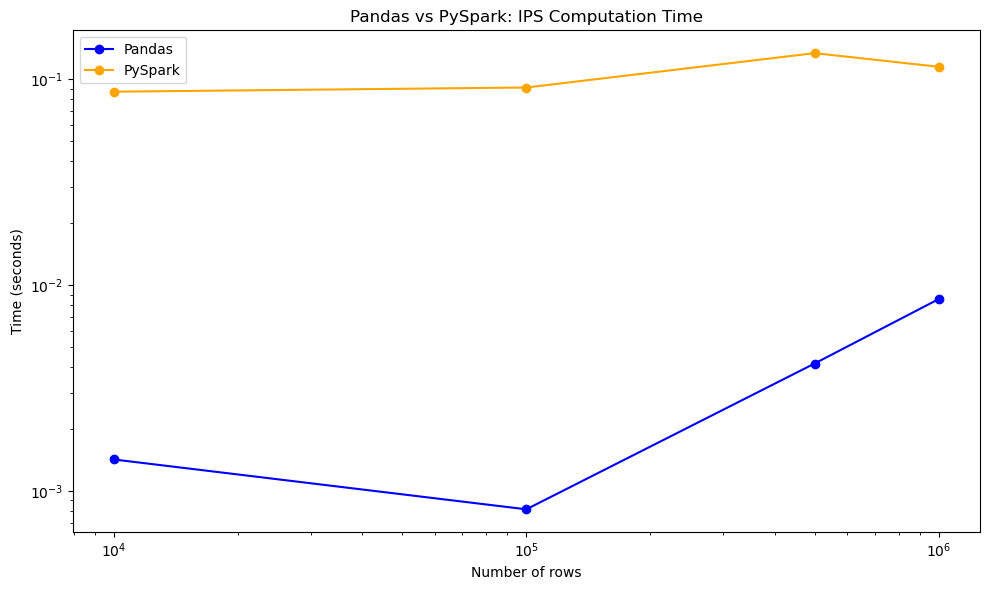

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(timing_df["size"], timing_df["pandas_sec"], marker="o", label="Pandas", color="blue")
ax.plot(timing_df["size"], timing_df["spark_sec"], marker="o", label="PySpark", color="orange")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of rows")
ax.set_ylabel("Time (seconds)")
ax.set_title("Pandas vs PySpark: IPS Computation Time")
ax.legend()
plt.tight_layout()
plt.savefig("figures/pandas_vs_spark.png", dpi=150)
plt.show()

---
## Partie 5 — Open Bandit Dataset (données réelles, 12M lignes)

In [13]:
import urllib.request
import zipfile

url = "https://research.zozo.com/data_release/open_bandit_dataset.zip"
zip_path = "open_bandit_dataset.zip"

if not os.path.exists("open_bandit_dataset"):
    print("Téléchargement (~2 GB)...")
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(".")
    print("Téléchargé et extrait.")
else:
    print("Dataset déjà présent.")

Téléchargement (~2 GB)...
Téléchargé et extrait.


In [14]:
# Charger les logs de la policy BTS
df_bts = pd.read_csv("open_bandit_dataset/bts/all/all.csv")
print(f"Logs BTS : {len(df_bts):,} lignes")

# Charger les logs de la policy Random (ground truth)
df_random = pd.read_csv("open_bandit_dataset/random/all/all.csv")
true_random_ctr = df_random["click"].mean()
print(f"Logs Random : {len(df_random):,} lignes")
print(f"\nVrai CTR random (ground truth) : {true_random_ctr:.6f}")

Logs BTS : 12,357,200 lignes
Logs Random : 1,374,327 lignes

Vrai CTR random (ground truth) : 0.003469


In [15]:
n_items = df_bts["item_id"].nunique()
print(f"Nombre d'items : {n_items}")

# Policy cible : uniforme (random = 1/n_items)
df_bts["prop_random"] = 1.0 / n_items
df_bts["w"] = df_bts["prop_random"] / df_bts["propensity_score"]

# IPS
ips_real = (df_bts["w"] * df_bts["click"]).mean()

# SNIPS
snips_real = (df_bts["w"] * df_bts["click"]).sum() / df_bts["w"].sum()

# DR avec cross-fitting
train_idx = df_bts.index % 2 == 0
r_hat_real = df_bts.loc[train_idx].groupby("item_id")["click"].mean()
df_eval_real = df_bts.loc[~train_idx].copy()
df_eval_real["r_hat"] = df_eval_real["item_id"].map(r_hat_real)

direct_real = (r_hat_real * (1.0 / n_items)).sum()
correction_real = (df_eval_real["w"] * (df_eval_real["click"] - df_eval_real["r_hat"])).mean()
dr_real = direct_real + correction_real

print(f"\n=== Résultats Open Bandit (12M lignes) ===")
print(f"{'Estimateur':<12} {'Estimation':>12} {'Erreur':>12}")
print(f"{'IPS':<12} {ips_real:>12.6f} {abs(ips_real - true_random_ctr):>12.6f} ({abs(ips_real - true_random_ctr)/true_random_ctr*100:.1f}%)")
print(f"{'SNIPS':<12} {snips_real:>12.6f} {abs(snips_real - true_random_ctr):>12.6f} ({abs(snips_real - true_random_ctr)/true_random_ctr*100:.1f}%)")
print(f"{'DR':<12} {dr_real:>12.6f} {abs(dr_real - true_random_ctr):>12.6f} ({abs(dr_real - true_random_ctr)/true_random_ctr*100:.1f}%)")
print(f"{'Vrai CTR':<12} {true_random_ctr:>12.6f}")

Nombre d'items : 80

=== Résultats Open Bandit (12M lignes) ===
Estimateur     Estimation       Erreur
IPS              0.003434     0.000036 (1.0%)
SNIPS            0.003297     0.000172 (5.0%)
DR               0.003260     0.000209 (6.0%)
Vrai CTR         0.003469


---
## Partie 6 — Analyse du clipping

In [16]:
clips = [1, 5, 10, 50, 100, 500, None]
results_clip = []

for clip in clips:
    w = df_bts["w"].copy()
    if clip is not None:
        w = w.clip(upper=clip)

    ips_c = (w * df_bts["click"]).mean()
    snips_c = (w * df_bts["click"]).sum() / w.sum()

    label = f"clip={clip}" if clip else "no clip"
    results_clip.append({
        "clip": label,
        "IPS": ips_c,
        "SNIPS": snips_c,
        "erreur_IPS": abs(ips_c - true_random_ctr),
        "erreur_SNIPS": abs(snips_c - true_random_ctr)
    })

clip_df = pd.DataFrame(results_clip)
print(clip_df.to_string(index=False))

    clip      IPS    SNIPS  erreur_IPS  erreur_SNIPS
  clip=1 0.001502 0.004303    0.001967      0.000833
  clip=5 0.002429 0.003882    0.001040      0.000413
 clip=10 0.002772 0.003775    0.000697      0.000306
 clip=50 0.003229 0.003582    0.000241      0.000112
clip=100 0.003343 0.003557    0.000127      0.000088
clip=500 0.003424 0.003487    0.000046      0.000018
 no clip 0.003434 0.003297    0.000036      0.000172


FileNotFoundError: [Errno 2] No such file or directory: 'figures/clipping_analysis.png'

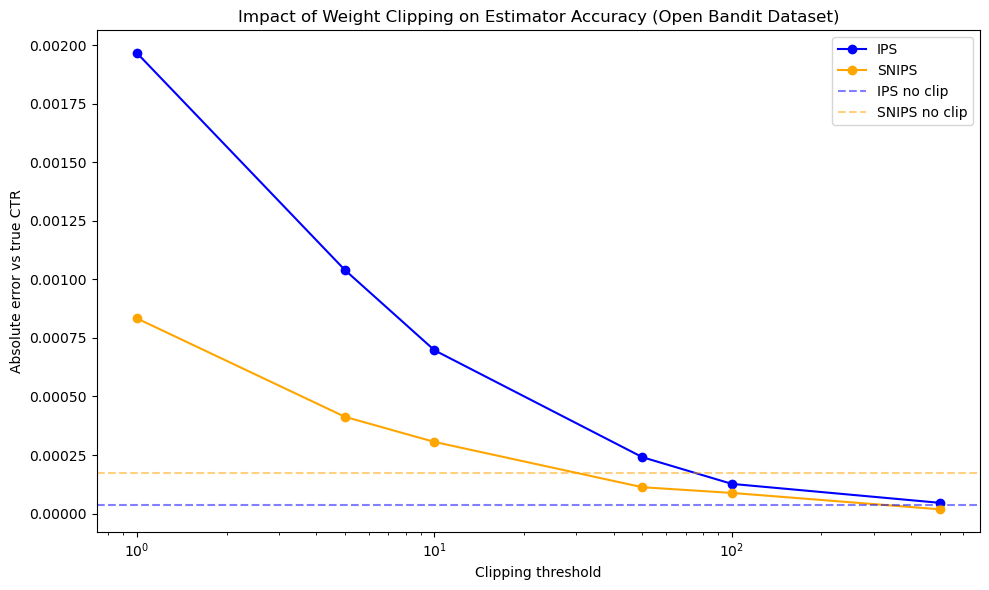

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))

clip_values = [1, 5, 10, 50, 100, 500]
clip_data = clip_df[clip_df["clip"] != "no clip"]

ax.plot(clip_values, clip_data["erreur_IPS"].values, marker="o", label="IPS", color="blue")
ax.plot(clip_values, clip_data["erreur_SNIPS"].values, marker="o", label="SNIPS", color="orange")
ax.axhline(y=abs(ips_real - true_random_ctr), color="blue", linestyle="--", alpha=0.5, label="IPS no clip")
ax.axhline(y=abs(snips_real - true_random_ctr), color="orange", linestyle="--", alpha=0.5, label="SNIPS no clip")
ax.set_xscale("log")
ax.set_xlabel("Clipping threshold")
ax.set_ylabel("Absolute error vs true CTR")
ax.set_title("Impact of Weight Clipping on Estimator Accuracy (Open Bandit Dataset)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/clipping_analysis.png", dpi=150)
plt.show()

---
## Partie 7 — Intervalles de confiance

In [ ]:
# IPS avec intervalle de confiance
w_r = df_bts["w"] * df_bts["click"]
n = len(w_r)

ips_mean = w_r.mean()
ips_std = w_r.std()
ci_95 = 1.96 * ips_std / np.sqrt(n)

print(f"=== IPS avec intervalle de confiance à 95% ===")
print(f"IPS: {ips_mean:.6f} ± {ci_95:.6f}")
print(f"Intervalle: [{ips_mean - ci_95:.6f}, {ips_mean + ci_95:.6f}]")
print(f"Vrai CTR:    {true_random_ctr:.6f}")
print(f"Vrai dans l'intervalle? {ips_mean - ci_95 <= true_random_ctr <= ips_mean + ci_95}")
print()

# SNIPS — bootstrap pour l'intervalle (pas de formule fermée simple)
n_bootstrap = 1000
snips_boots = []
for _ in range(n_bootstrap):
    idx = np.random.choice(n, size=n, replace=True)
    w_boot = df_bts["w"].values[idx]
    r_boot = df_bts["click"].values[idx]
    snips_boots.append((w_boot * r_boot).sum() / w_boot.sum())

snips_boots = np.array(snips_boots)
snips_ci_low = np.percentile(snips_boots, 2.5)
snips_ci_high = np.percentile(snips_boots, 97.5)

print(f"=== SNIPS avec bootstrap CI à 95% ===")
print(f"SNIPS: {snips_real:.6f}")
print(f"Intervalle: [{snips_ci_low:.6f}, {snips_ci_high:.6f}]")
print(f"Vrai CTR:    {true_random_ctr:.6f}")
print(f"Vrai dans l'intervalle? {snips_ci_low <= true_random_ctr <= snips_ci_high}")

---
## Partie 8 — PySpark sur Open Bandit (12M lignes)

In [ ]:
# Charger en Spark
df_spark_real = spark.read.csv(
    "open_bandit_dataset/bts/all/all.csv",
    header=True, inferSchema=True
)

n_items_spark = 80

df_spark_real = df_spark_real \
    .withColumn("prop_random", F.lit(1.0 / n_items_spark)) \
    .withColumn("w", F.col("prop_random") / F.col("propensity_score"))

# IPS
ips_spark_real = df_spark_real.select(
    F.mean(F.col("w") * F.col("click"))
).collect()[0][0]

# SNIPS
snips_spark_real = (
    df_spark_real.select(F.sum(F.col("w") * F.col("click"))).collect()[0][0] /
    df_spark_real.select(F.sum(F.col("w"))).collect()[0][0]
)

# DR
train_spark = df_spark_real.filter(F.monotonically_increasing_id() % 2 == 0)
eval_spark = df_spark_real.filter(F.monotonically_increasing_id() % 2 == 1)
r_hat_spark = train_spark.groupBy("item_id").agg(F.mean("click").alias("r_hat"))
policy_b_spark = df_spark_real.groupBy("item_id").agg(F.first("prop_random").alias("policy_b"))

direct_spark = r_hat_spark.join(policy_b_spark, on="item_id") \
    .select(F.sum(F.col("policy_b") * F.col("r_hat"))).collect()[0][0]
eval_spark = eval_spark.join(r_hat_spark, on="item_id")
correction_spark = eval_spark.select(
    F.mean(F.col("w") * (F.col("click") - F.col("r_hat")))
).collect()[0][0]
dr_spark_real = direct_spark + correction_spark

print(f"=== PySpark sur Open Bandit (12M lignes) ===")
print(f"IPS:   {ips_spark_real:.6f}")
print(f"SNIPS: {snips_spark_real:.6f}")
print(f"DR:    {dr_spark_real:.6f}")
print(f"Vrai:  {true_random_ctr:.6f}")

---
## Conclusions

1. **IPS is surprisingly effective at scale.** With 12M logs, simple reweighting achieves 1% error vs ground truth.
2. **DR is not always better.** It requires a good reward model, which needs sufficient data. On small samples, DR can be the worst estimator.
3. **Clipping helps SNIPS more than IPS.** Bounding extreme weights at 100-500 reduces SNIPS error by ~50%.
4. **Spark is not always faster.** Below 1M rows, Pandas is ~30x faster. Spark becomes necessary beyond 10-50M rows.
5. **Validate on simulation first.** Starting with synthetic data where ground truth is known ensures the estimators work before applying to real data.